In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("Yahoo-Finance-Ticker-Symbols.csv")

In [3]:
df.head()

,Ticker,Name,Exchange,Category Name,Country
0,OEDV,"Osage Exploration and Development, Inc.",PNK,NaN,USA
1,AAPL,Apple Inc.,NMS,Electronic Equipment,USA
2,BAC,Bank of America Corporation,NYQ,Money Center Banks,USA
3,AMZN,"Amazon.com, Inc.",NMS,Catalog & Mail Order Houses,USA
4,T,AT&T Inc.,NYQ,Telecom Services - Domestic,USA


In [4]:
df_usa = df[df['Country']=="USA"]
df_usa.shape

(22170, 5)

In [5]:
df_usa["Exchange"].unique()

<ArrowStringArray>
['PNK', 'NMS', 'NYQ', 'NCM', 'NGM', 'ASE', 'OBB', 'PCX']
Length: 8, dtype: str

In [6]:
df_usa_nyse = df_usa[df_usa["Exchange"]=="NYQ"]
df_usa_nyse.shape

(3384, 5)

In [ ]:
df_usa_nyse.head()

,Ticker,Name,Exchange,Category Name,Country
2,BAC,Bank of America Corporation,NYQ,Money Center Banks,USA
4,T,AT&T Inc.,NYQ,Telecom Services - Domestic,USA
6,MO,"Altria Group, Inc.",NYQ,Cigarettes,USA
7,DAL,"Delta Air Lines, Inc.",NYQ,Major Airlines,USA
8,AA,Alcoa Corporation,NYQ,Aluminum,USA


In [8]:
import yfinance as yf


In [12]:
tickers = df_usa_nyse["Ticker"].dropna().unique().tolist()
len(tickers)

3384

In [13]:
from tqdm.auto import tqdm

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# batch_size = 50
# price_batches = []

# for i in tqdm(range(0, len(tickers), batch_size), desc="Downloading prices"):
#     batch = tickers[i:i + batch_size]

#     data = yf.download(
#         batch,
#         period="3y",
#         auto_adjust=True,
#         progress=False,
#         threads=False
#     )["Close"]

#     price_batches.append(data)

# prices = pd.concat(price_batches, axis=1)

In [ ]:
# prices.index.name = "Date"
# prices.to_csv("nyse_stock_prices.csv", index=True)

In [16]:
prices = pd.read_csv("nyse_stock_prices.csv", index_col="Date", parse_dates=True)
prices.shape

(752, 3384)

In [17]:
prices.head()

,A,AA,AB,ABBV,ABT,ABX,ACN,ADM,AEM,AEO,...,TRW,TTM-RI,UMH-PA,USB-PH,UTX-PA,VLY-WT,VNO-PG,WRI-PF,WRI-PFCL,WRK-WI
Date,,,,,,,,,,,,,,,,,,,,,
2023-11-03,106.614372,25.688955,22.275602,127.992737,89.980995,6.432384,295.673676,65.950966,47.021320,16.943825,...,NaN,NaN,NaN,16.135361,NaN,NaN,NaN,NaN,NaN,NaN
2023-11-06,105.157265,25.146706,22.212852,127.793625,89.192352,6.597318,295.296417,65.634377,46.736111,16.815807,...,NaN,NaN,NaN,16.249912,NaN,NaN,NaN,NaN,NaN,NaN
2023-11-07,108.100838,24.730341,21.804987,128.662476,89.004585,6.694337,297.277100,65.227325,45.794930,16.852386,...,NaN,NaN,NaN,16.331734,NaN,NaN,NaN,NaN,NaN,NaN
2023-11-08,106.976219,24.720654,21.734398,128.544815,88.948242,6.791356,299.757629,65.154961,44.606560,17.044407,...,NaN,NaN,NaN,16.323551,NaN,NaN,NaN,NaN,NaN,NaN
2023-11-09,105.362617,23.800770,21.303003,124.933662,87.831017,6.771952,296.362244,65.272568,44.977329,16.834099,...,NaN,NaN,NaN,16.249912,NaN,NaN,NaN,NaN,NaN,NaN


In [18]:
prices = prices.sort_index()
prices = prices.loc[:, prices.iloc[0].notna()]
print("Remaining stocks:", prices.shape[1])

Remaining stocks: 1540


In [19]:
prices.head()

,A,AA,AB,ABBV,ABT,ABX,ACN,ADM,AEM,AEO,...,JPM-PC,JPM-PD,LXP-PC,MS-PE,NU,PSA-PO,RGP,MET-PA,SR,USB-PH
Date,,,,,,,,,,,,,,,,,,,,,
2023-11-03,106.614372,25.688955,22.275602,127.992737,89.980995,6.432384,295.673676,65.950966,47.021320,16.943825,...,20.849054,20.095020,36.496540,20.646444,8.48,14.048678,11.720511,19.280893,52.117840,16.135361
2023-11-06,105.157265,25.146706,22.212852,127.793625,89.192352,6.597318,295.296417,65.634377,46.736111,16.815807,...,20.782236,20.044699,36.403496,20.533358,8.31,13.956692,11.762580,19.189711,51.020901,16.249912
2023-11-07,108.100838,24.730341,21.804987,128.662476,89.004585,6.694337,297.277100,65.227325,45.794930,16.852386,...,20.790586,19.935671,35.941933,20.533358,8.45,13.781083,11.569061,19.198004,50.792736,16.331734
2023-11-08,106.976219,24.720654,21.734398,128.544815,88.948242,6.791356,299.757629,65.154961,44.606560,17.044407,...,20.798941,19.969217,36.190269,20.581820,8.33,13.789447,11.468096,19.156553,50.064365,16.323551
2023-11-09,105.362617,23.800770,21.303003,124.933662,87.831017,6.771952,296.362244,65.272568,44.977329,16.834099,...,20.615173,19.709227,36.117752,20.412193,8.26,13.588750,11.442853,19.106819,50.160896,16.249912


In [20]:
daily_returns = prices.pct_change(fill_method=None).iloc[1:]
daily_returns.head()

,A,AA,AB,ABBV,ABT,ABX,ACN,ADM,AEM,AEO,...,JPM-PC,JPM-PD,LXP-PC,MS-PE,NU,PSA-PO,RGP,MET-PA,SR,USB-PH
Date,,,,,,,,,,,,,,,,,,,,,
2023-11-06,-0.013667,-0.021108,-0.002817,-0.001556,-0.008765,0.025641,-0.001276,-0.004800,-0.006066,-0.007555,...,-0.003205,-0.002504,-0.002549,-0.005477,-0.020047,-0.006548,0.003589,-0.004729,-0.021047,0.007099
2023-11-07,0.027992,-0.016557,-0.018362,0.006799,-0.002105,0.014706,0.006707,-0.006202,-0.020138,0.002175,...,0.000402,-0.005439,-0.012679,0.000000,0.016847,-0.012582,-0.016452,0.000432,-0.004472,0.005035
2023-11-08,-0.010403,-0.000392,-0.003237,-0.000914,-0.000633,0.014493,0.008344,-0.001109,-0.025950,0.011394,...,0.000402,0.001683,0.006909,0.002360,-0.014201,0.000607,-0.008727,-0.002159,-0.014340,-0.000501
2023-11-09,-0.015084,-0.037211,-0.019848,-0.028093,-0.012560,-0.002857,-0.011327,0.001805,0.008312,-0.012339,...,-0.008835,-0.013020,-0.002004,-0.008242,-0.008403,-0.014554,-0.002201,-0.002596,0.001928,-0.004511
2023-11-10,0.006776,0.002441,-0.019882,0.003984,0.004489,-0.021490,0.017408,0.004712,-0.005284,0.009234,...,0.002836,0.003830,0.011803,0.002374,0.031477,0.002794,0.007353,0.002169,-0.004199,0.002517


In [21]:
corr_matrix = daily_returns.corr(method="pearson")


In [22]:
corr_matrix.to_csv("nyse_correlation_matrix.csv", index=True)


In [23]:
print("Shape:", corr_matrix.shape)
print("Missing values:", corr_matrix.isna().sum().sum())

Shape: (1540, 1540)
Missing values: 0


In [24]:
corr_matrix.head()

,A,AA,AB,ABBV,ABT,ABX,ACN,ADM,AEM,AEO,...,JPM-PC,JPM-PD,LXP-PC,MS-PE,NU,PSA-PO,RGP,MET-PA,SR,USB-PH
A,1.000000,0.295281,0.240899,0.279117,0.205538,0.089074,0.214961,0.110076,0.157939,0.304770,...,0.153375,0.174897,0.016514,0.120963,0.180996,0.188903,0.275528,0.149515,0.061804,0.103447
AA,0.295281,1.000000,0.211547,0.061172,-0.011334,0.110911,0.103230,0.190963,0.346147,0.218908,...,0.207304,0.245702,0.039091,0.138714,0.252744,0.188905,0.202882,0.163325,0.106554,0.126166
AB,0.240899,0.211547,1.000000,0.148973,0.206272,0.136868,0.213895,0.135351,0.114010,0.206000,...,0.187307,0.235241,0.020094,0.110519,0.185847,0.209036,0.231616,0.200860,0.200357,0.231349
ABBV,0.279117,0.061172,0.148973,1.000000,0.299289,0.071974,0.135396,0.115951,0.058662,0.070500,...,0.005713,0.028216,0.048330,0.040256,0.045660,0.106263,0.105992,0.046834,0.205706,0.073500
ABT,0.205538,-0.011334,0.206272,0.299289,1.000000,0.066018,0.212662,0.104475,0.074305,0.078056,...,0.100106,0.096900,0.037637,0.083930,0.023424,0.075142,0.109228,0.081121,0.238610,0.094749


In [25]:
# Remove stocks with undefined correlations
corr_matrix = corr_matrix.dropna(axis=0, how="any")
corr_matrix = corr_matrix.dropna(axis=1, how="any")


In [27]:
import numpy as np

In [28]:
# Calculate financial distance matrix
distance_matrix = np.sqrt(2 * (1 - corr_matrix.clip(-1, 1)))

In [30]:
distance_matrix.head()

,A,AA,AB,ABBV,ABT,ABX,ACN,ADM,AEM,AEO,...,JPM-PC,JPM-PD,LXP-PC,MS-PE,NU,PSA-PO,RGP,MET-PA,SR,USB-PH
A,0.000000,1.187198,1.232153,1.200736,1.260525,1.349760,1.253027,1.334109,1.297737,1.179178,...,1.301249,1.284604,1.402488,1.325924,1.279847,1.273654,1.203721,1.304212,1.369814,1.339069
AA,1.187198,0.000000,1.255749,1.370276,1.422205,1.333483,1.339231,1.272035,1.143550,1.249873,...,1.259124,1.228249,1.386297,1.312468,1.222502,1.273652,1.262631,1.293580,1.336747,1.321994
AB,1.232153,1.255749,0.000000,1.304628,1.259943,1.313873,1.253878,1.315027,1.331157,1.260159,...,1.274906,1.236737,1.399933,1.333778,1.276051,1.257747,1.239664,1.264231,1.264628,1.239880
ABBV,1.200736,1.370276,1.304628,0.000000,1.183816,1.362370,1.314993,1.329699,1.372106,1.363452,...,1.410168,1.394119,1.379616,1.385456,1.381550,1.336965,1.337167,1.380699,1.260392,1.361250
ABT,1.260525,1.422205,1.259943,1.183816,0.000000,1.366735,1.254861,1.338302,1.360658,1.357898,...,1.341562,1.343950,1.387345,1.353565,1.397552,1.360043,1.334745,1.355639,1.234010,1.345549


In [31]:
distance_matrix.to_csv("nyse_distance_matrix.csv", index=True)


In [32]:
print("Shape:", distance_matrix.shape)
print("Min distance:", distance_matrix.min().min())
print("Max distance:", distance_matrix.max().max())

Shape: (1540, 1540)
Min distance: 0.0
Max distance: 1.6367077226704614


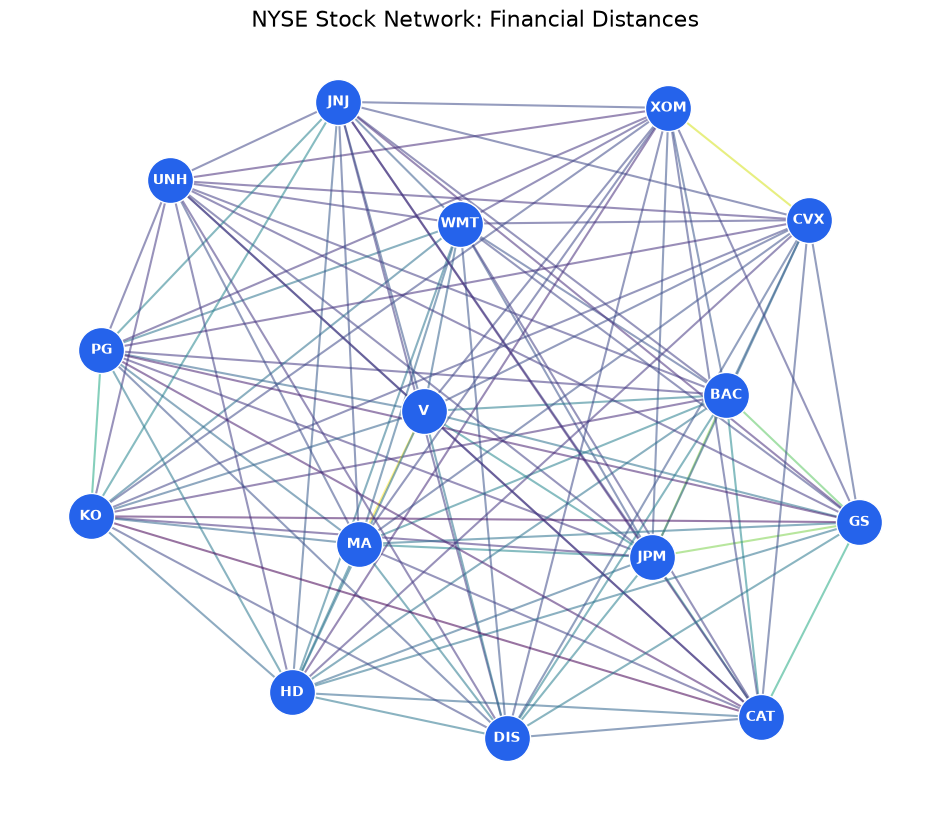

In [39]:
import networkx as nx
import matplotlib.pyplot as plt

# Select 15 major NYSE stocks
tickers = [
    "JPM", "BAC", "WMT", "XOM", "JNJ",
    "V", "MA", "UNH", "HD", "PG",
    "KO", "DIS", "CAT", "GS", "CVX"
]

# Keep only available tickers
tickers = [t for t in tickers if t in distance_matrix.columns]
D = distance_matrix.loc[tickers, tickers]

# Create complete weighted graph
G = nx.from_pandas_adjacency(D)

# Position nodes using financial distances
pos = nx.kamada_kawai_layout(G, weight="weight")

plt.figure(figsize=(12, 10))

nx.draw_networkx_nodes(
    G, pos, node_size=1100,
    node_color="#2563eb", edgecolors="white"
)

nx.draw_networkx_labels(
    G, pos, font_size=10,
    font_weight="bold", font_color="white"
)

nx.draw_networkx_edges(
    G, pos,
    edge_color=list(nx.get_edge_attributes(G, "weight").values()),
    edge_cmap=plt.cm.viridis_r,
    width=1.5, alpha=0.55
)

plt.title("NYSE Stock Network: Financial Distances", fontsize=16)
plt.axis("off")
plt.show()

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/networkx/drawing/nx_pylab.py:137: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  super().__init__(self.x, self.y, *args, rotation=self.angle, **kwargs)


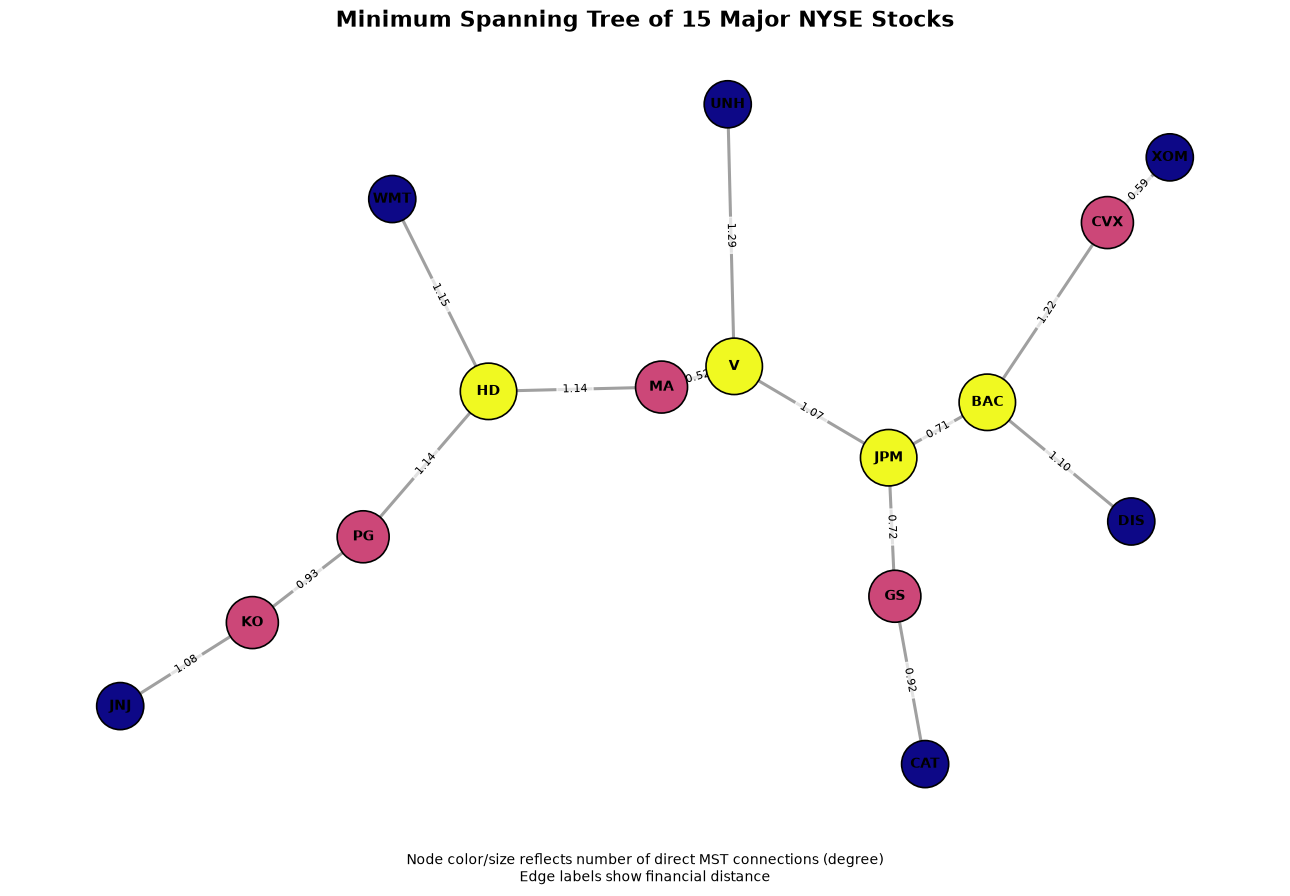

In [41]:
import networkx as nx
import matplotlib.pyplot as plt

# Same 15 stocks
tickers = [
    "JPM", "BAC", "WMT", "XOM", "JNJ",
    "V", "MA", "UNH", "HD", "PG",
    "KO", "DIS", "CAT", "GS", "CVX"
]

# Keep only tickers present in distance_matrix
tickers = [t for t in tickers if t in distance_matrix.index]

# Subset distance matrix
D = distance_matrix.loc[tickers, tickers]

# Build full weighted graph
G_full = nx.from_pandas_adjacency(D)

# Compute MST
G_mst = nx.minimum_spanning_tree(G_full, weight="weight")

# Layout
pos = nx.kamada_kawai_layout(G_mst, weight="weight")

# Node degrees in MST
degree = dict(G_mst.degree())

# Plot
plt.figure(figsize=(13, 9))
ax = plt.gca()
ax.set_facecolor("white")

# Draw edges
edge_weights = nx.get_edge_attributes(G_mst, "weight")
nx.draw_networkx_edges(
    G_mst, pos,
    width=2.2,
    edge_color="gray",
    alpha=0.75
)

# Draw nodes
nx.draw_networkx_nodes(
    G_mst, pos,
    node_size=[900 + 250 * degree[n] for n in G_mst.nodes()],
    node_color=list(degree.values()),
    cmap=plt.cm.plasma,
    edgecolors="black",
    linewidths=1.2
)

# Draw labels
nx.draw_networkx_labels(
    G_mst, pos,
    font_size=10,
    font_weight="bold"
)

# Edge labels = financial distance
edge_labels = {(u, v): f"{w:.2f}" for (u, v), w in edge_weights.items()}
nx.draw_networkx_edge_labels(
    G_mst, pos,
    edge_labels=edge_labels,
    font_size=8,
    bbox=dict(alpha=0.7, color="white", edgecolor="none")
)

plt.title("Minimum Spanning Tree of 15 Major NYSE Stocks", fontsize=16, weight="bold")
plt.text(
    0.5, -0.06,
    "Node color/size reflects number of direct MST connections (degree)\nEdge labels show financial distance",
    ha="center", transform=ax.transAxes, fontsize=10
)
plt.axis("off")
plt.tight_layout()
plt.show()

In [43]:
import networkx as nx
import numpy as np

# 1. Degree centrality
centrality = nx.degree_centrality(G_mst)
print("Degree centrality:")
print(sorted(centrality.items(), key=lambda x: x[1], reverse=True))

# 2. Average edge distance
avg_distance = np.mean([
    data["weight"] for _, _, data in G_mst.edges(data=True)
])
print("Average edge distance:", round(avg_distance, 4))

# 3. Industry Composition

# Map tickers to industries
industry_map = df_usa_nyse.set_index("Ticker")["Category Name"].to_dict()

# Identify industry relationships in MST
same_industry = []
different_industry = []

for u, v in G_mst.edges():
    if industry_map.get(u) == industry_map.get(v):
        same_industry.append((u, v))
    else:
        different_industry.append((u, v))

# Calculate industry similarity
similarity = 100 * len(same_industry) / G_mst.number_of_edges()

print(f"Same industry edges: {len(same_industry)}")
print(f"Different industry edges: {len(different_industry)}")
print(f"Industry similarity: {similarity:.2f}%")
print("Same industry connections:", same_industry)

Degree centrality:
[('JPM', 0.21428571428571427), ('BAC', 0.21428571428571427), ('V', 0.21428571428571427), ('HD', 0.21428571428571427), ('MA', 0.14285714285714285), ('PG', 0.14285714285714285), ('KO', 0.14285714285714285), ('GS', 0.14285714285714285), ('CVX', 0.14285714285714285), ('WMT', 0.07142857142857142), ('XOM', 0.07142857142857142), ('JNJ', 0.07142857142857142), ('UNH', 0.07142857142857142), ('DIS', 0.07142857142857142), ('CAT', 0.07142857142857142)]
Average edge distance: 0.9698
Same industry edges: 3
Different industry edges: 11
Industry similarity: 21.43%
Same industry connections: [('JPM', 'BAC'), ('XOM', 'CVX'), ('V', 'MA')]


,Observations,Average Distance,Industry Similarity (%),Top 3 Hubs
Regime,,,,
Normal,41,0.957,21.429,"PG, BAC, XOM"
Crisis,42,0.628,14.286,"GS, V, MA"
Boom,41,0.805,21.429,"HD, JPM, JNJ"


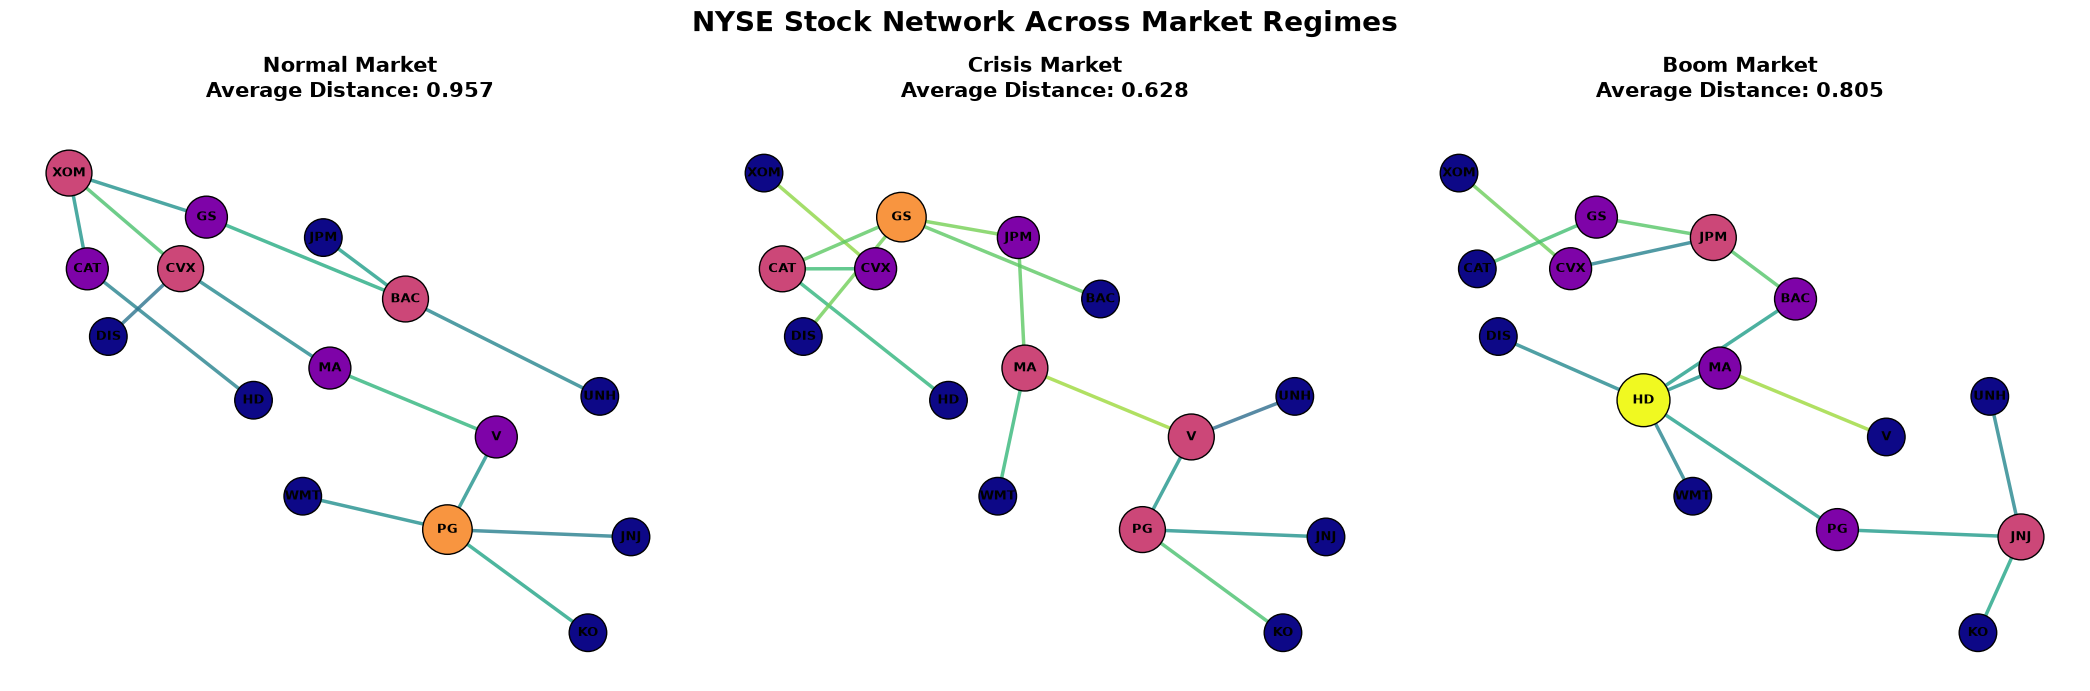

In [45]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# 1. Define market periods
periods = {
    "Normal": ("2024/05/01", "2024/06/30"),
    "Crisis": ("2025/03/01", "2025/04/30"),
    "Boom":   ("2025/05/01", "2025/06/30")
}

# Same 15 stocks
tickers = [
    "JPM", "BAC", "WMT", "XOM", "JNJ",
    "V", "MA", "UNH", "HD", "PG",
    "KO", "DIS", "CAT", "GS", "CVX"
]

daily_returns.index = pd.to_datetime(daily_returns.index)

industry_map = df_usa_nyse.set_index("Ticker")["Category Name"].to_dict()

trees = {}
results = []

# 2. Calculate MST for each period
for regime, (start, end) in periods.items():

    returns = daily_returns.loc[start:end, tickers].dropna()

    if len(returns) < 20:
        raise ValueError(f"Insufficient observations for {regime}")

    corr = returns.corr()

    if corr.isna().any().any():
        raise ValueError(f"Undefined correlations in {regime}")

    D = np.sqrt(2 * np.subtract(1, corr.clip(np.negative(1), 1)))
    # np.fill_diagonal(D.values, 0)

    G = nx.from_pandas_adjacency(D)
    T = nx.minimum_spanning_tree(G, weight="weight")

    trees[regime] = T

    weights = nx.get_edge_attributes(T, "weight")
    centrality = nx.degree_centrality(T)

    same = sum(
        industry_map.get(u) == industry_map.get(v)
        and pd.notna(industry_map.get(u))
        for u, v in T.edges()
    )

    results.append({
        "Regime": regime,
        "Observations": len(returns),
        "Average Distance": np.mean(list(weights.values())),
        "Industry Similarity (%)": 100 * same / T.number_of_edges(),
        "Top 3 Hubs": ", ".join(
            sorted(centrality, key=centrality.get, reverse=True)[:3]
        )
    })

# 3. Compare metrics
comparison = pd.DataFrame(results).set_index("Regime")
display(comparison.round(3))

# 4. Visualize all three MSTs
combined = nx.compose_all(list(trees.values()))
pos = nx.spring_layout(combined, seed=42, weight=None)

fig, axes = plt.subplots(1, 3, figsize=(21, 7))

for ax, (regime, T) in zip(axes, trees.items()):

    degree = dict(T.degree())
    weights = [d["weight"] for u, v, d in T.edges(data=True)]

    nx.draw_networkx_edges(
        T, pos, ax=ax,
        edge_color=weights,
        edge_cmap=plt.cm.viridis_r,
        edge_vmin=0, edge_vmax=2,
        width=2.5, alpha=0.8
    )

    nx.draw_networkx_nodes(
        T, pos, ax=ax,
        node_size=[550 + 180 * degree[n] for n in T],
        node_color=[degree[n] for n in T],
        cmap=plt.cm.plasma,
        vmin=1, vmax=5,
        edgecolors="black"
    )

    nx.draw_networkx_labels(
        T, pos, ax=ax,
        font_size=9, font_weight="bold"
    )

    ax.set_title(
        f"{regime} Market\nAverage Distance: {np.mean(weights):.3f}",
        fontsize=15, fontweight="bold", pad=20
    )
    ax.axis("off")

plt.suptitle(
    "NYSE Stock Network Across Market Regimes",
    fontsize=20, fontweight="bold"
)

plt.tight_layout()
plt.show()

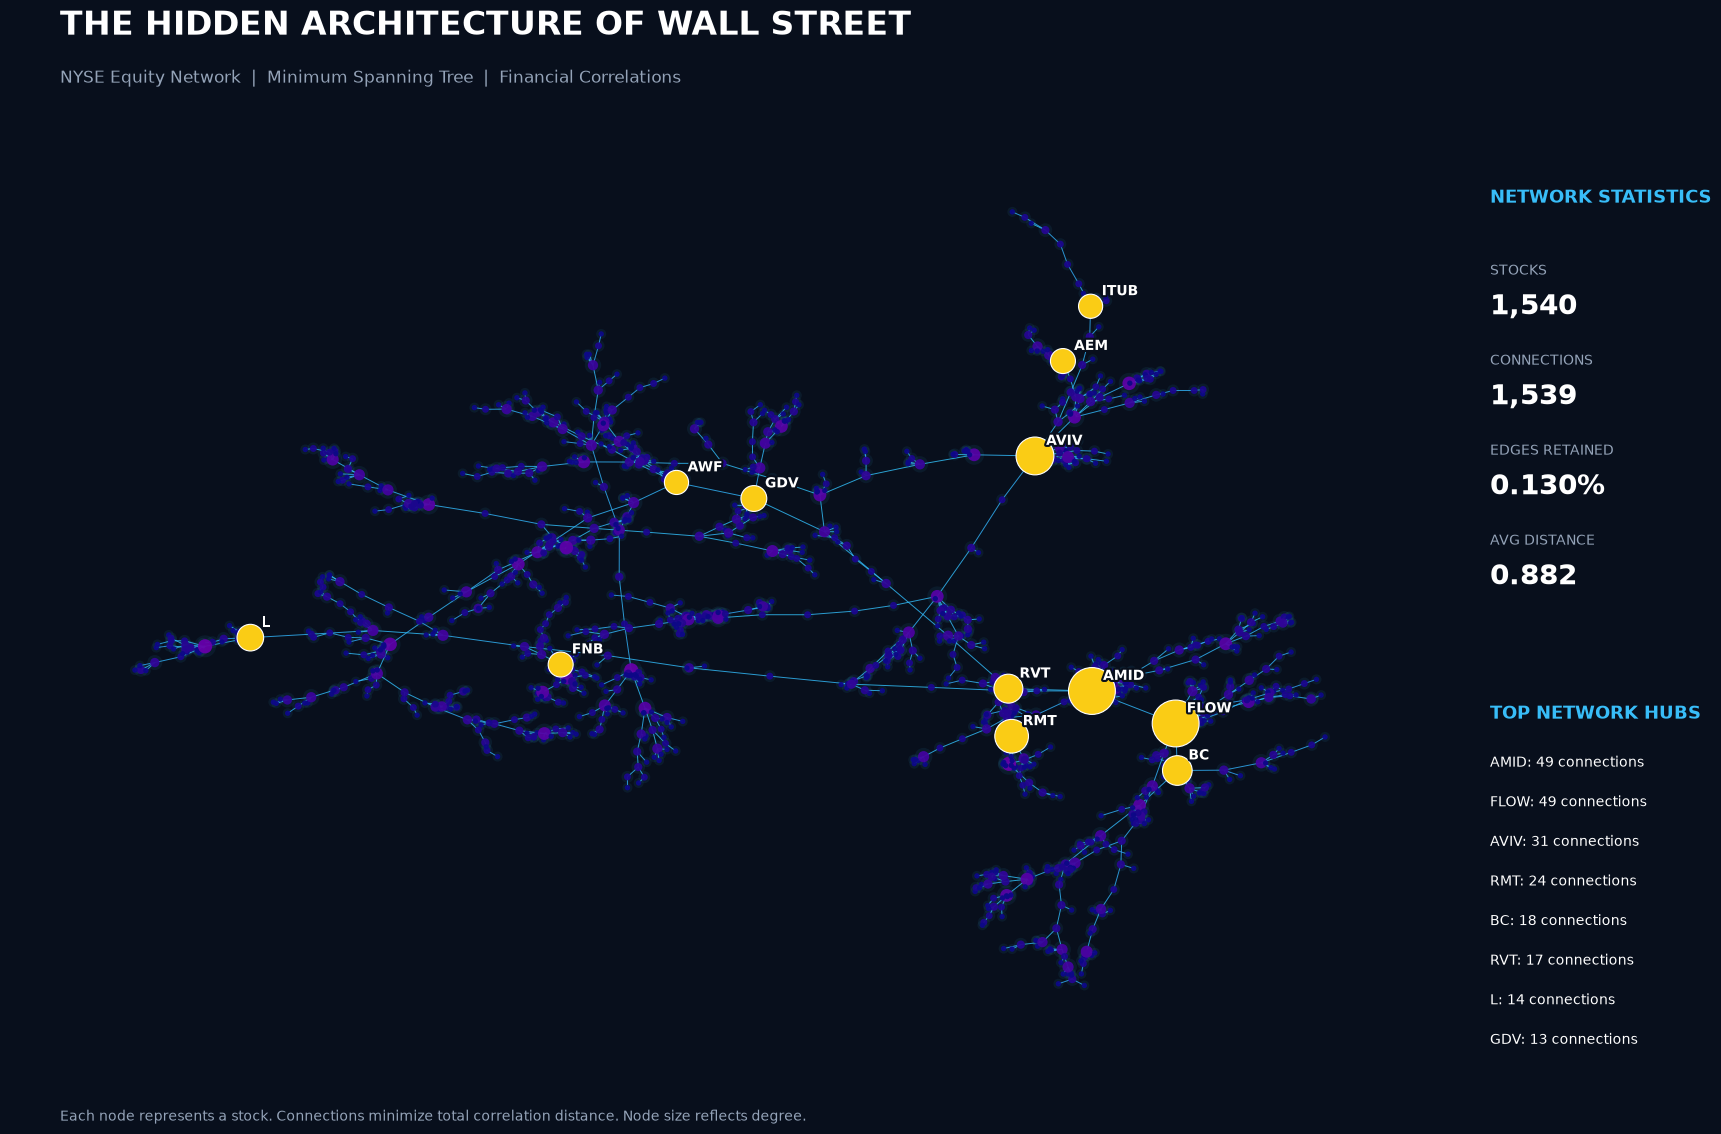

In [47]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from scipy.sparse.csgraph import minimum_spanning_tree

# 1. Construct MST using ALL stocks
D = distance_matrix.copy()

mst = minimum_spanning_tree(D.values)
G = nx.from_scipy_sparse_array(mst)
G = nx.relabel_nodes(G, dict(enumerate(D.index)))

n = G.number_of_nodes()
degree = dict(G.degree())
hubs = sorted(degree, key=degree.get, reverse=True)[:12]

# 2. Layout optimized for large networks
try:
    from networkx.drawing.nx_agraph import graphviz_layout
    pos = graphviz_layout(G, prog="sfdp")
except ImportError:
    pos = nx.spring_layout(
        G, seed=42, iterations=120,
        weight=None
    )

# 3. Financial similarity
weights = np.array([
    data["weight"]
    for u, v, data in G.edges(data=True)
])

similarity = np.clip(np.subtract(2, weights) / 2, 0, 1)

edge_colors = [
    (0.2, 0.55 + 0.3*s, 1.0, 0.12 + 0.6*s)
    for s in similarity
]

# 4. Figure
bg = "#080F1C"

fig = plt.figure(figsize=(20, 12), facecolor=bg)
ax = fig.add_axes([0.03, 0.08, 0.72, 0.78])
ax.set_facecolor(bg)

# Edges
nx.draw_networkx_edges(
    G, pos, ax=ax,
    edge_color=edge_colors,
    width=0.7,
    alpha=0.8
)

# Node glow
nx.draw_networkx_nodes(
    G, pos, ax=ax,
    node_size=[30 + 22*degree[t] for t in G],
    node_color="#38BDF8",
    alpha=0.07,
    linewidths=0
)

# Main nodes
nodes = nx.draw_networkx_nodes(
    G, pos, ax=ax,
    node_size=[5 + 10*degree[t] for t in G],
    node_color=[degree[t] for t in G],
    cmap="plasma",
    edgecolors="none",
    alpha=0.95
)

# Highlight hubs
nx.draw_networkx_nodes(
    G, pos, nodelist=hubs,
    ax=ax,
    node_size=[60 + 22*degree[t] for t in hubs],
    node_color="#FACC15",
    edgecolors="white",
    linewidths=0.8
)

# Hub labels
for ticker in hubs:
    x, y = pos[ticker]

    label = ax.annotate(
        ticker, (x, y),
        xytext=(8, 8),
        textcoords="offset points",
        color="white",
        fontsize=10,
        fontweight="bold"
    )

    label.set_path_effects([
        pe.withStroke(linewidth=3, foreground=bg)
    ])

ax.axis("off")

# 5. Typography
fig.text(
    0.055, 0.94,
    "THE HIDDEN ARCHITECTURE OF WALL STREET",
    color="white",
    fontsize=24,
    fontweight="bold"
)

fig.text(
    0.055, 0.90,
    "NYSE Equity Network  |  Minimum Spanning Tree  |  Financial Correlations",
    color="#94A3B8",
    fontsize=12
)

# 6. Statistics panel
fig.text(
    0.77, 0.80,
    "NETWORK STATISTICS",
    color="#38BDF8",
    fontsize=13,
    fontweight="bold"
)

stats = [
    ("STOCKS", f"{n:,}"),
    ("CONNECTIONS", f"{G.number_of_edges():,}"),
    ("EDGES RETAINED", f"{200/n:.3f}%"),
    ("AVG DISTANCE", f"{weights.mean():.3f}")
]

for i, (name, value) in enumerate(stats):
    y = 0.74 + np.negative(i * 0.075)

    fig.text(0.77, y, name, color="#94A3B8", fontsize=10)
    fig.text(
        0.77, y + np.negative(0.033),
        value, color="white",
        fontsize=20, fontweight="bold"
    )

# Top hubs
fig.text(
    0.77, 0.37,
    "TOP NETWORK HUBS",
    color="#38BDF8",
    fontsize=13,
    fontweight="bold"
)

for i, ticker in enumerate(hubs[:8]):
    fig.text(
        0.77,
        0.33 + np.negative(i * 0.033),
        f"{ticker}: {degree[ticker]} connections",
        color="white",
        fontsize=10
    )

# 7. Footer
fig.text(
    0.055, 0.035,
    "Each node represents a stock. Connections minimize total correlation distance."
    " Node size reflects degree.",
    color="#94A3B8",
    fontsize=10
)

# 8. Export
plt.savefig(
    "NYSE_Full_MST.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=bg
)

plt.show()